<a href="https://colab.research.google.com/github/BenjaminBustamanteRosales/optimizacion-centros-acopio-python/blob/main/Optimizacion_Trabajo_Grupal_Grupo_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
seed = 1   # <-- reemplazar por el número asignado a su grupo

assert seed != 0, "Reemplace seed por el número asignado a su grupo"
rs = np.random.RandomState(seed)

In [4]:
# Coordenadas base (km) del centro de cada sector de la comuna
sector_xy = np.array([[2.0,10.0],[7.0,11.0],[12.5,10.0],[2.5,5.0],[7.5,6.0],[13.0,5.0],[8.0,1.5]])

# Generación base de material reciclable por sector (ton/semana)
generacion_base = np.array([90,120,70,150,180,100,110])

# Sector donde se ubica cada sitio candidato
sitio_sector = np.array([1,2,3,4,5,5,6,7,7])

# Coordenadas base (km) de cada sitio candidato
sitio_xy = np.array([[2.6,9.4],[6.6,10.4],[11.8,9.6],[3.2,5.4],[7.0,6.6],
                     [8.4,5.4],[12.4,5.6],[7.4,2.0],[8.8,1.8]])

# Capacidad base de cada sitio (ton/semana)
capacidad_base = np.array([200,300,160,260,320,220,200,180,160])

# Costo fijo base de operación de cada sitio (millones de pesos por año)
costo_fijo_base = np.array([60,110,50,90,120,85,70,55,50])

In [5]:
# Perturbación de ubicaciones (±0,6 km)
sector_xy = sector_xy + rs.uniform(-0.6, 0.6, sector_xy.shape)
sitio_xy = sitio_xy + rs.uniform(-0.6, 0.6, sitio_xy.shape)

# Perturbación de la generación (±15%)
generacion = (generacion_base*(1 + rs.uniform(-0.15, 0.15, len(generacion_base)))).astype(int)

# Perturbación de capacidades (±10%)
capacidad = (capacidad_base*(1 + rs.uniform(-0.10, 0.10, len(capacidad_base)))).astype(int)

# Perturbación de costos fijos (±20%)
costo_fijo = (costo_fijo_base*(1 + rs.uniform(-0.20, 0.20, len(costo_fijo_base)))).astype(int)

# Asegurar factibilidad (aun operando solo uno de los sitios 1 y 4)
cap_sin_humedal = capacidad.sum() - max(capacidad[0], capacidad[3])
if cap_sin_humedal < 1.1*generacion.sum():
    factor = 1.1*generacion.sum()/cap_sin_humedal
    capacidad = (capacidad*factor).astype(int) + 1

# Costo de transporte ($ por tonelada-km)
costo_ton_km = int(rs.randint(24, 35)*100)

# Distancia promedio de recorrido sector-sitio (km): distancia en línea recta
# por un factor 1,3 de recorrido por calles, con un mínimo de 0,8 km
dif = sector_xy[:, None, :] - sitio_xy[None, :, :]
distancia = np.sqrt((dif**2).sum(axis=2))*1.3
distancia = np.maximum(distancia, 0.8).round(1)

In [6]:
sectores = np.arange(1, 8)

df_generacion = pd.DataFrame({
    "Sector": sectores,
    "Generación (ton/semana)": generacion
})
df_generacion.loc["Total"] = ["", generacion.sum()]

print("GENERACIÓN DE MATERIAL RECICLABLE POR SECTOR")
display(df_generacion.style.hide(axis="index"))

GENERACIÓN DE MATERIAL RECICLABLE POR SECTOR


Sector,Generación (ton/semana)
1,82
2,113
3,65
4,158
5,178
6,112
7,118
,826


In [7]:
sitios = np.arange(1, 10)

df_sitios = pd.DataFrame({
    "Sitio": sitios,
    "Sector del sitio": sitio_sector,
    "Capacidad (ton/semana)": capacidad,
    "Costo fijo (MM$/año)": costo_fijo
})
df_sitios.loc["Total"] = ["", "", capacidad.sum(), ""]

print("DATOS DE LOS SITIOS CANDIDATOS")
display(df_sitios.style.hide(axis="index"))

DATOS DE LOS SITIOS CANDIDATOS


Sitio,Sector del sitio,Capacidad (ton/semana),Costo fijo (MM$/año)
1,1,214,64
2,2,296,126
3,3,175,55
4,4,283,104
5,5,347,117
6,5,220,98
7,6,184,66
8,7,187,46
9,7,159,42
,,2065,


In [8]:
print(f"COSTO DE TRANSPORTE: {costo_ton_km} $ por tonelada-km")

COSTO DE TRANSPORTE: 2600 $ por tonelada-km


In [9]:
df_distancia = pd.DataFrame(distancia,
                            index=pd.Index(sectores, name="Sector \\ Sitio"),
                            columns=sitios)

print("DISTANCIA PROMEDIO DE RECORRIDO SECTOR-SITIO (km)")
display(df_distancia.style.format("{:.1f}"))

DISTANCIA PROMEDIO DE RECORRIDO SECTOR-SITIO (km)


,1,2,3,4,5,6,7,8,9
Sector \ Sitio,,,,,,,,,
1,1.5,6.4,13.4,6.3,8.9,11.0,15.2,13.6,13.9
2,6.6,1.8,6.6,8.8,5.5,8.1,10.0,12.0,11.9
3,13.4,7.8,0.9,13.8,7.9,8.9,6.4,12.6,12.0
4,6.2,9.0,14.7,2.0,7.8,8.2,13.4,8.4,9.1
5,9.0,5.8,7.5,6.7,1.8,0.9,5.4,4.9,4.7
6,15.0,10.4,6.7,12.8,7.4,5.9,1.1,7.5,6.7
7,12.6,11.1,12.4,8.4,7.2,4.8,7.9,0.8,1.3


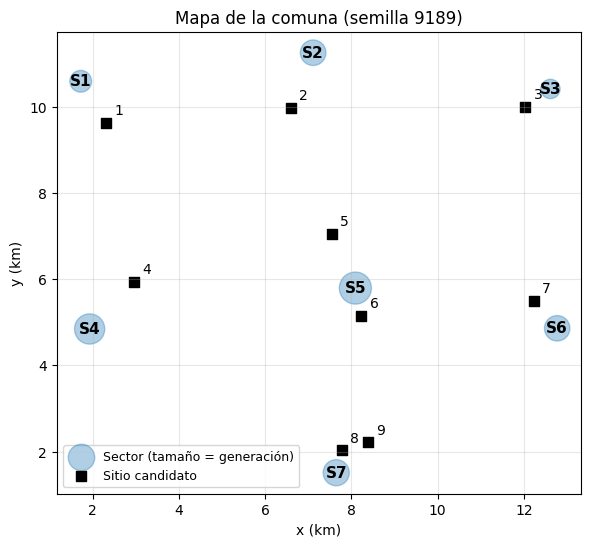

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(sector_xy[:, 0], sector_xy[:, 1], s=generacion*3, alpha=0.35, label="Sector (tamaño = generación)")
for i in range(len(sectores)):
    ax.annotate(f"S{i+1}", sector_xy[i], ha="center", va="center", fontsize=11, fontweight="bold")
ax.scatter(sitio_xy[:, 0], sitio_xy[:, 1], marker="s", s=60, color="black", label="Sitio candidato")
for j in range(len(sitios)):
    ax.annotate(f"{j+1}", sitio_xy[j], xytext=(6, 6), textcoords="offset points", fontsize=10)
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
ax.set_title(f"Mapa de la comuna (semilla {seed})")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="lower left", fontsize=9)
plt.show()

In [11]:
# Fijamos la versión de PuLP para que el código funcione igual en cualquier computador
!pip -q install "pulp==2.9.0"

import pulp
print("PuLP versión:", pulp.__version__)
print("Solvers disponibles:", pulp.listSolvers(onlyAvailable=True))

PuLP versión: 2.9.0
Solvers disponibles: ['PULP_CBC_CMD', 'HiGHS']


## Herramientas de modelamiento
Aunque el enunciado menciona AMPL, el modelo se implementa en Python con la librería **PuLP**,
que permite declarar variables, función objetivo y restricciones de forma muy similar a AMPL.
El problema se resuelve con el solver **CBC** (branch and bound), adecuado para
problemas lineales con variables binarias (MILP).

In [12]:
# ---------- CONJUNTOS ----------
I = [int(s) for s in sectores]   # I: sectores de la comuna (1..7)
J = [int(s) for s in sitios]     # J: sitios candidatos para centros de acopio (1..9)

# ---------- PARÁMETROS ----------
# Se usan diccionarios indexados con la misma numeración del enunciado (empieza en 1),
# para evitar confusiones con los índices de 0 de numpy.
g = {i: float(generacion[i-1]) for i in I}   # g[i]: generación del sector i [ton/semana]
K = {j: float(capacidad[j-1]) for j in J}    # K[j]: capacidad máxima del sitio j [ton/semana]
F = {j: float(costo_fijo[j-1]) for j in J}   # F[j]: costo fijo anual del sitio j [MM$/año]
c = float(costo_ton_km)                      # c: costo de transporte [$/ton-km]
d = {(i, j): float(distancia[i-1, j-1]) for i in I for j in J}  # d[i,j]: distancia sector i -> sitio j [km]

SEMANAS = 52      # semanas de operación por año [sem/año]
PESOS_A_MM = 1e6  # conversión de $ a MM$ [$ / MM$]

# ---------- CHEQUEOS BÁSICOS ----------
print("Generación total [ton/sem]:", sum(g.values()))
print("Capacidad total  [ton/sem]:", sum(K.values()))
assert sum(K.values()) >= sum(g.values()), "Infactible: la capacidad total no alcanza"

Generación total [ton/sem]: 826.0
Capacidad total  [ton/sem]: 2065.0


## Conjuntos y parámetros
- **I** = {1,...,7}: sectores de la comuna. **J** = {1,...,9}: sitios candidatos.
- **g_i** [ton/semana]: material reciclable generado en el sector i.
- **K_j** [ton/semana]: capacidad máxima de procesamiento del sitio j.
- **F_j** [MM$/año]: costo fijo anual de operar el sitio j (solo se paga si opera).
- **c** [$/ton-km]: costo de transporte. **d_ij** [km]: distancia promedio de recorrido sector i -> sitio j
  (nunca es cero porque incluye el recorrido dentro del propio sector).
- **Conversión de unidades:** el transporte semanal está en $ (c · d · x). Para expresarlo
  en MM$/año se multiplica por 52 semanas/año y se divide por 10^6:
  [$/ton-km]·[km]·[ton/sem]·[sem/año] / [$/MM$] = [MM$/año], igual que los costos fijos.

In [13]:
def construir_modelo_base(c_transp):
    """Modelo base (P1). Recibe el costo de transporte para poder reutilizarlo en la sensibilidad (P4)."""
    m = pulp.LpProblem("Centros_de_acopio_base", pulp.LpMinimize)

    # VARIABLE: y[j] = 1 si el sitio j opera, 0 si no (decisión de apertura)
    y = {j: pulp.LpVariable(f"opera_sitio_{j}", cat="Binary") for j in J}

    # VARIABLE: x[i,j] = toneladas semanales que el sector i envía al sitio j (continua, >= 0)
    x = {(i, j): pulp.LpVariable(f"ton_semana_envio_{i}_{j}", lowBound=0) for i in I for j in J}

    # EXPRESIONES DEL OBJETIVO (ambas en MM$/año)
    costo_fijo_anual = pulp.lpSum(F[j] * y[j] for j in J)
    costo_transporte_anual = pulp.lpSum(c_transp * d[i, j] * x[i, j] for i in I for j in J) * SEMANAS / PESOS_A_MM

    # FUNCIÓN OBJETIVO: minimizar costo total anual = costos fijos + transporte
    m += costo_fijo_anual + costo_transporte_anual, "Costo_total_anual_MM"

    # RESTRICCIÓN: todo el material de cada sector debe procesarse (se puede repartir entre varios sitios)
    for i in I:
        m += pulp.lpSum(x[i, j] for j in J) == g[i], f"Procesar_todo_sector_{i}"

    # RESTRICCIÓN: un sitio solo recibe material si opera, y nunca más que su capacidad
    for j in J:
        m += pulp.lpSum(x[i, j] for i in I) <= K[j] * y[j], f"Capacidad_si_opera_sitio_{j}"

    return m, x, y

## Modelo base (Pregunta 1)
**Variables**
- y_j ∈ {0,1}: vale 1 si el sitio j opera. Es binaria porque el costo fijo se paga completo o no se paga.
- x_ij ≥ 0 [ton/semana]: material del sector i enviado al sitio j. Es continua porque el enunciado
  permite repartir un sector entre varios centros.

**Función objetivo** (MM$/año):
min  Σ_j F_j·y_j + (52·c / 10^6) · Σ_i Σ_j d_ij·x_ij

**Restricciones**
1. Σ_j x_ij = g_i, para todo i: todo lo generado se procesa.
2. Σ_i x_ij ≤ K_j·y_j, para todo j: si y_j = 0 el sitio no recibe nada; si y_j = 1, respeta su capacidad.
   Esta restricción es la que enlaza las variables binarias con los flujos.

In [14]:
def resolver_y_resumir(m, x, y, c_transp, nombre):
    """Resuelve el modelo y entrega tablas: centros que operan, flujos, uso (%) y desglose de costos."""
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    estado = pulp.LpStatus[m.status]
    print(f"=== {nombre} ===")
    print("Estado del solver:", estado)
    if estado != "Optimal":
        return None

    abiertos = [j for j in J if y[j].value() > 0.5]

    # Matriz de flujos sector x sitio [ton/semana]
    flujo = pd.DataFrame({j: [x[i, j].value() for i in I] for j in J},
                         index=pd.Index(I, name="Sector \\ Sitio")).round(2)

    # Tabla por sitio: opera, carga, capacidad, uso (%) y costo fijo
    filas = []
    for j in J:
        opera = j in abiertos
        carga = flujo[j].sum()
        filas.append({
            "Sitio": j,
            "Opera": "Sí" if opera else "No",
            "Carga (ton/sem)": round(carga, 2),
            "Capacidad (ton/sem)": K[j],
            "Uso (%)": round(100 * carga / K[j], 1) if opera else 0.0,
            "Costo fijo (MM$/año)": F[j] if opera else 0.0,
        })
    tabla_sitios = pd.DataFrame(filas)

    # Desglose de costos (MM$/año)
    costo_fijo_total = sum(F[j] for j in abiertos)
    costo_transp_total = sum(c_transp * d[i, j] * x[i, j].value() for i in I for j in J) * SEMANAS / PESOS_A_MM
    costo_total = pulp.value(m.objective)
    assert abs(costo_fijo_total + costo_transp_total - costo_total) < 1e-3  # chequeo de consistencia

    print("Centros que operan:", abiertos)
    print(f"Costo fijo:        {costo_fijo_total:,.2f} MM$/año")
    print(f"Costo transporte:  {costo_transp_total:,.2f} MM$/año")
    print(f"Costo total:       {costo_total:,.2f} MM$/año")
    print("\nUso y costos por sitio")
    display(tabla_sitios.style.hide(axis="index"))
    print("\nToneladas semanales enviadas (solo sitios que operan)")
    display(flujo[abiertos])

    return {"abiertos": abiertos, "flujo": flujo, "tabla_sitios": tabla_sitios,
            "fijo": costo_fijo_total, "transporte": costo_transp_total, "total": costo_total}

# ---- Resolver la Pregunta 1 ----
m1, x1, y1 = construir_modelo_base(c)
res1 = resolver_y_resumir(m1, x1, y1, c, "Pregunta 1: modelo base")

=== Pregunta 1: modelo base ===
Estado del solver: Optimal
Centros que operan: [3, 4, 6, 7, 8]
Costo fijo:        369.00 MM$/año
Costo transporte:  273.00 MM$/año
Costo total:       642.00 MM$/año

Uso y costos por sitio


Sitio,Opera,Carga (ton/sem),Capacidad (ton/sem),Uso (%),Costo fijo (MM$/año)
1,No,0.000000,214.000000,0.000000,0.000000
2,No,0.000000,296.000000,0.000000,0.000000
3,Sí,175.000000,175.000000,100.000000,55.000000
4,Sí,240.000000,283.000000,84.800000,104.000000
5,No,0.000000,347.000000,0.000000,0.000000
6,Sí,181.000000,220.000000,82.300000,98.000000
7,Sí,112.000000,184.000000,60.900000,66.000000
8,Sí,118.000000,187.000000,63.100000,46.000000
9,No,0.000000,159.000000,0.000000,0.000000



Toneladas semanales enviadas (solo sitios que operan)


,3,4,6,7,8
Sector \ Sitio,,,,,
1,0.0,82.0,0.0,0.0,0.0
2,110.0,0.0,3.0,0.0,0.0
3,65.0,0.0,0.0,0.0,0.0
4,0.0,158.0,0.0,0.0,0.0
5,0.0,0.0,178.0,0.0,0.0
6,0.0,0.0,0.0,112.0,0.0
7,0.0,0.0,0.0,0.0,118.0


## Resultados del modelo base
Se resuelve el modelo con CBC y se reportan: los centros que operan, las toneladas semanales
que cada sector envía a cada centro, el porcentaje de uso de cada centro (carga / capacidad)
y el costo total anual separado en costo fijo y costo de transporte.

**Interpretación** (completar cuando tengamos la semilla definitiva):
- Qué sitios se abren y por qué (relación entre su costo fijo, su capacidad y su cercanía a los sectores).
- Si algún sector reparte su material entre más de un centro, y a qué se debe (capacidad limitada).
- Si el costo fijo o el transporte domina el costo total.

In [15]:
def construir_modelo_normativo(c_transp):
    """Escenario normativo (P2): modelo base + restricción de humedal + uso mínimo del 50%."""
    # Reutilizamos el modelo base (mismas variables, objetivo y restricciones de P1)
    m, x, y = construir_modelo_base(c_transp)
    m.name = "Centros_de_acopio_normativo"

    # RESTRICCIÓN NUEVA: los sitios 1 y 4 colindan con el humedal; opera a lo más uno de ellos
    m += y[1] + y[4] <= 1, "Humedal_a_lo_mas_uno_de_sitios_1_y_4"

    # RESTRICCIÓN NUEVA: contrato; todo centro que opera procesa al menos 50% de su capacidad semanal
    # (si y[j] = 0 queda 0 >= 0, o sea no obliga a nada)
    FRACCION_MIN = 0.5  # fracción mínima de uso exigida por contrato [adimensional]
    for j in J:
        m += pulp.lpSum(x[i, j] for i in I) >= FRACCION_MIN * K[j] * y[j], f"Uso_minimo_50pct_sitio_{j}"

    return m, x, y

# ---- Resolver la Pregunta 2 ----
m2, x2, y2 = construir_modelo_normativo(c)
res2 = resolver_y_resumir(m2, x2, y2, c, "Pregunta 2: escenario normativo")

=== Pregunta 2: escenario normativo ===
Estado del solver: Optimal
Centros que operan: [3, 4, 6, 7, 8]
Costo fijo:        369.00 MM$/año
Costo transporte:  273.00 MM$/año
Costo total:       642.00 MM$/año

Uso y costos por sitio


Sitio,Opera,Carga (ton/sem),Capacidad (ton/sem),Uso (%),Costo fijo (MM$/año)
1,No,0.000000,214.000000,0.000000,0.000000
2,No,0.000000,296.000000,0.000000,0.000000
3,Sí,175.000000,175.000000,100.000000,55.000000
4,Sí,240.000000,283.000000,84.800000,104.000000
5,No,0.000000,347.000000,0.000000,0.000000
6,Sí,181.000000,220.000000,82.300000,98.000000
7,Sí,112.000000,184.000000,60.900000,66.000000
8,Sí,118.000000,187.000000,63.100000,46.000000
9,No,0.000000,159.000000,0.000000,0.000000



Toneladas semanales enviadas (solo sitios que operan)


,3,4,6,7,8
Sector \ Sitio,,,,,
1,0.0,82.0,0.0,0.0,0.0
2,110.0,0.0,3.0,0.0,0.0
3,65.0,0.0,0.0,0.0,0.0
4,0.0,158.0,0.0,0.0,0.0
5,0.0,0.0,178.0,0.0,0.0
6,0.0,0.0,0.0,112.0,0.0
7,0.0,0.0,0.0,0.0,118.0


## Escenario normativo (Pregunta 2)
Se parte del modelo base y se agregan dos restricciones, sin modificar variables ni función objetivo:

1. **Humedal:** y_1 + y_4 ≤ 1. Los sitios 1 y 4 colindan con el humedal protegido y la autoridad
   autoriza que opere a lo más uno de ellos.
2. **Uso mínimo por contrato:** Σ_i x_ij ≥ 0,5 · K_j · y_j, para todo j.
   Si el sitio opera (y_j = 1) debe recibir al menos 50 % de su capacidad; si no opera (y_j = 0)
   la restricción se reduce a 0 ≥ 0 y no tiene efecto. Por eso se multiplica por y_j: sin ese factor
   se obligaría a todos los sitios a recibir material, incluso los cerrados.

In [16]:
# ---------- TABLA COMPARATIVA DE COSTOS (MM$/año) ----------
comparacion = pd.DataFrame({
    "P1: base": [str(res1["abiertos"]), res1["fijo"], res1["transporte"], res1["total"]],
    "P2: normativo": [str(res2["abiertos"]), res2["fijo"], res2["transporte"], res2["total"]],
}, index=["Centros que operan", "Costo fijo (MM$/año)", "Costo transporte (MM$/año)", "Costo total (MM$/año)"])
display(comparacion)

dif = res2["total"] - res1["total"]
print(f"Diferencia de costo total (P2 - P1): {dif:,.2f} MM$/año ({100*dif/res1['total']:.2f} %)")

# ---------- DIAGNÓSTICO: ¿QUÉ CONDICIÓN PROVOCÓ EL CAMBIO? ----------
print("\nDiagnóstico de la solución base (P1) frente a las condiciones de P2:")
print("- ¿Operan los sitios 1 y 4 a la vez en P1?:", (1 in res1["abiertos"]) and (4 in res1["abiertos"]))
usos_p1 = res1["tabla_sitios"].query("Opera == 'Sí'")[["Sitio", "Uso (%)"]]
print("- Uso (%) de los centros que operan en P1 (¿alguno bajo 50 %?):")
display(usos_p1.style.hide(axis="index"))

# ---------- CAMBIOS EN FLUJOS ----------
print("Cambio en toneladas enviadas (P2 - P1), por sector y sitio:")
display((res2["flujo"] - res1["flujo"]).round(2))

,P1: base,P2: normativo
Centros que operan,"[3, 4, 6, 7, 8]","[3, 4, 6, 7, 8]"
Costo fijo (MM$/año),369.0,369.0
Costo transporte (MM$/año),272.99584,272.99584
Costo total (MM$/año),641.99584,641.99584


Diferencia de costo total (P2 - P1): 0.00 MM$/año (0.00 %)

Diagnóstico de la solución base (P1) frente a las condiciones de P2:
- ¿Operan los sitios 1 y 4 a la vez en P1?: False
- Uso (%) de los centros que operan en P1 (¿alguno bajo 50 %?):


Sitio,Uso (%)
3,100.000000
4,84.800000
6,82.300000
7,60.900000
8,63.100000


Cambio en toneladas enviadas (P2 - P1), por sector y sitio:


,1,2,3,4,5,6,7,8,9
Sector \ Sitio,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Comparación P1 vs P2
Se compara qué centros operan, el costo fijo, el costo de transporte y el costo total.

**Interpretación** (completar con la semilla definitiva):
- Qué centros cambian entre P1 y P2 y cuál de las dos condiciones lo provocó
  (el diagnóstico muestra si P1 violaba el humedal o el 50 % de uso).
- Por qué el costo de P2 es mayor o igual que el de P1: P2 agrega restricciones al mismo problema
  de minimización, así que su región factible es un subconjunto de la de P1 y su óptimo no puede ser mejor.
  Si el costo es idéntico, significa que la solución de P1 ya cumplía ambas condiciones.
- Si la diferencia de costo tiene sentido: qué componente (fijo o transporte) cambia más y por qué.

In [17]:
# ---------- PREGUNTA 4: costo de transporte +50% ----------
AUMENTO = 0.5                       # aumento del costo por ton-km [adimensional]
c_alto = c * (1 + AUMENTO)          # nuevo costo de transporte [$/ton-km]
print(f"Costo de transporte base: {c:,.0f} $/ton-km  ->  con alza: {c_alto:,.0f} $/ton-km")

m4, x4, y4 = construir_modelo_base(c_alto)
res4 = resolver_y_resumir(m4, x4, y4, c_alto, "Pregunta 4: transporte +50%")

# ---------- COMPARACIÓN P1 (c base) vs P4 (c alto) ----------
comp4 = pd.DataFrame({
    "P1: c base": [str(res1["abiertos"]), len(res1["abiertos"]), res1["fijo"], res1["transporte"], res1["total"]],
    "P4: c +50%": [str(res4["abiertos"]), len(res4["abiertos"]), res4["fijo"], res4["transporte"], res4["total"]],
}, index=["Centros que operan", "Número de centros", "Costo fijo (MM$/año)",
          "Costo transporte (MM$/año)", "Costo total (MM$/año)"])
display(comp4)

# Distancia media recorrida por tonelada [km/ton]: transporte anual / (c * 52 * toneladas semanales)
def km_por_ton(res, c_transp):
    return res["transporte"] * PESOS_A_MM / (c_transp * SEMANAS * sum(g.values()))
print(f"Distancia media por tonelada: P1 = {km_por_ton(res1, c):.2f} km | P4 = {km_por_ton(res4, c_alto):.2f} km")

# ---------- CHEQUEO TEÓRICO ----------
# La solución de P1 sigue siendo factible con c alto y costaría fijo + 1.5*transporte;
# por lo tanto el óptimo de P4 no puede superar ese valor.
cota = res1["fijo"] + (1 + AUMENTO) * res1["transporte"]
print(f"Costo P4 = {res4['total']:,.2f} <= cota (P1 re-evaluada) = {cota:,.2f}")
assert res4["total"] <= cota + 1e-6

# ---------- CAMBIO EN LOS CENTROS ----------
print("Centros que dejan de operar:", sorted(set(res1["abiertos"]) - set(res4["abiertos"])))
print("Centros que comienzan a operar:", sorted(set(res4["abiertos"]) - set(res1["abiertos"])))

Costo de transporte base: 2,600 $/ton-km  ->  con alza: 3,900 $/ton-km
=== Pregunta 4: transporte +50% ===
Estado del solver: Optimal
Centros que operan: [1, 3, 4, 6, 7, 8]
Costo fijo:        433.00 MM$/año
Costo transporte:  328.76 MM$/año
Costo total:       761.76 MM$/año

Uso y costos por sitio


Sitio,Opera,Carga (ton/sem),Capacidad (ton/sem),Uso (%),Costo fijo (MM$/año)
1,Sí,195.000000,214.000000,91.100000,64.000000
2,No,0.000000,296.000000,0.000000,0.000000
3,Sí,65.000000,175.000000,37.100000,55.000000
4,Sí,158.000000,283.000000,55.800000,104.000000
5,No,0.000000,347.000000,0.000000,0.000000
6,Sí,178.000000,220.000000,80.900000,98.000000
7,Sí,112.000000,184.000000,60.900000,66.000000
8,Sí,118.000000,187.000000,63.100000,46.000000
9,No,0.000000,159.000000,0.000000,0.000000



Toneladas semanales enviadas (solo sitios que operan)


,1,3,4,6,7,8
Sector \ Sitio,,,,,,
1,82.0,0.0,0.0,0.0,0.0,0.0
2,113.0,0.0,0.0,0.0,0.0,0.0
3,0.0,65.0,0.0,0.0,0.0,0.0
4,0.0,0.0,158.0,0.0,0.0,0.0
5,0.0,0.0,0.0,178.0,0.0,0.0
6,0.0,0.0,0.0,0.0,112.0,0.0
7,0.0,0.0,0.0,0.0,0.0,118.0


,P1: c base,P4: c +50%
Centros que operan,"[3, 4, 6, 7, 8]","[1, 3, 4, 6, 7, 8]"
Número de centros,5,6
Costo fijo (MM$/año),369.0,433.0
Costo transporte (MM$/año),272.99584,328.75908
Costo total (MM$/año),641.99584,761.75908


Distancia media por tonelada: P1 = 2.44 km | P4 = 1.96 km
Costo P4 = 761.76 <= cota (P1 re-evaluada) = 778.49
Centros que dejan de operar: []
Centros que comienzan a operar: [1]


## Sensibilidad: transporte +50 % (Pregunta 4)
Se resuelve nuevamente el modelo de la Pregunta 1 con c' = 1,5·c, manteniendo capacidades,
costos fijos y distancias.

**Qué esperamos, y por qué.** El costo fijo no depende del costo de transporte, pero el término de
transporte sí. Al subir c, mover una tonelada por kilómetro se vuelve más caro, así que
las distancias pesan más en la decisión. Hay dos efectos que compiten:
- abrir un centro adicional cercano a un sector cuesta su costo fijo F_j, pero ahorra transporte;
- cerrar centros ahorra costo fijo, pero obliga a recorrer distancias mayores.
Si c sube, el ahorro por transporte de un centro cercano crece y puede superar a su costo fijo.

**Cota teórica.** La solución óptima de P1 sigue siendo factible con el nuevo c, con costo
F + 1,5·T (F: costo fijo, T: transporte de P1). Como P4 es un problema de minimización, su
costo óptimo es menor o igual que ese valor: el costo total sube **a lo más** 50 % del
transporte, no 50 % del total, y baja más si el modelo reorganiza los centros.

**Interpretación** (completar con la semilla definitiva):
- ¿Cambia el número o la ubicación de los centros? ¿Cuáles se abren o se cierran?
- ¿Qué pasa con la distancia media por tonelada y con la proporción fijo/transporte?
- Si no cambió nada, explicar por qué: el ahorro de transporte de abrir otro centro sigue siendo menor que su costo fijo.

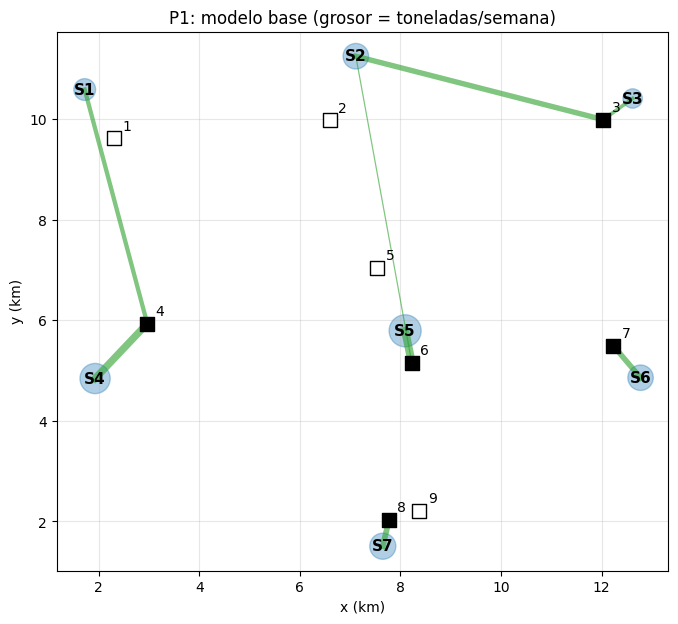

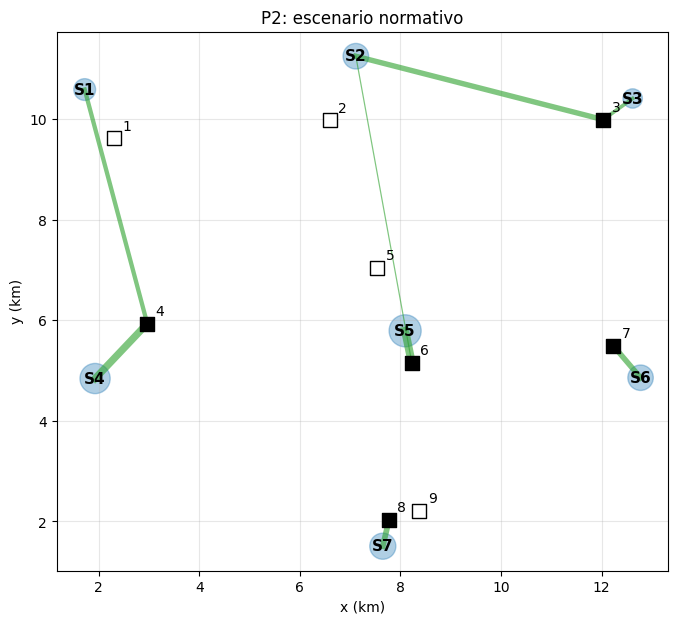

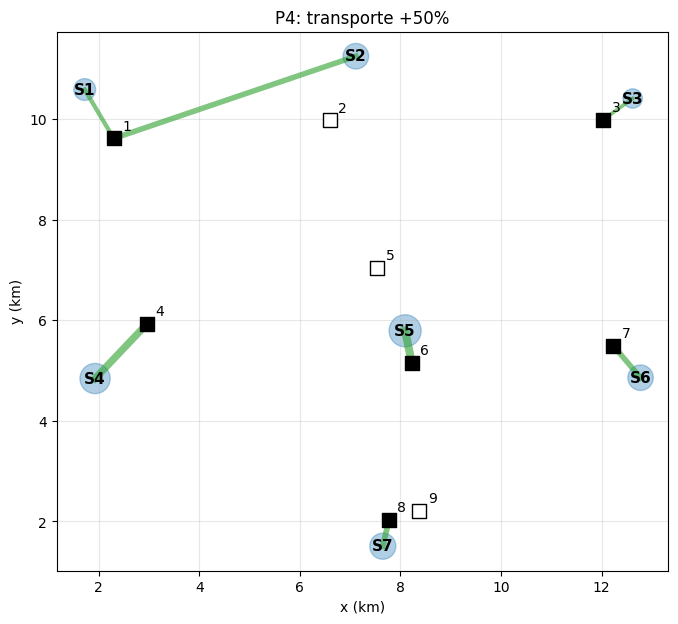

In [18]:
def graficar_solucion(res, titulo):
    """Mapa de la comuna: sectores, sitios (negro = opera, blanco = cerrado) y flujos (grosor = ton/sem)."""
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(sector_xy[:, 0], sector_xy[:, 1], s=generacion * 3, alpha=0.35, label="Sector (tamaño = generación)")
    for i in I:
        ax.annotate(f"S{i}", sector_xy[i-1], ha="center", va="center", fontsize=11, fontweight="bold")

    flujo = res["flujo"]
    max_flujo = flujo.values.max()
    for i in I:
        for j in res["abiertos"]:
            t = flujo.loc[i, j]
            if t > 0.01:   # solo dibujamos flujos positivos
                ax.plot([sector_xy[i-1, 0], sitio_xy[j-1, 0]], [sector_xy[i-1, 1], sitio_xy[j-1, 1]],
                        color="tab:green", alpha=0.6, linewidth=0.8 + 5 * t / max_flujo)

    for j in J:
        opera = j in res["abiertos"]
        ax.scatter(sitio_xy[j-1, 0], sitio_xy[j-1, 1], marker="s", s=90,
                   color="black" if opera else "white", edgecolor="black", zorder=3)
        ax.annotate(f"{j}", sitio_xy[j-1], xytext=(6, 6), textcoords="offset points", fontsize=10)

    ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
    ax.set_title(titulo); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    plt.show()

graficar_solucion(res1, "P1: modelo base (grosor = toneladas/semana)")
graficar_solucion(res2, "P2: escenario normativo")
graficar_solucion(res4, "P4: transporte +50%")

## Visualización de las soluciones
Cada mapa muestra los 7 sectores (círculos, tamaño proporcional a la generación) y los 9 sitios
candidatos (cuadrados: negro si opera, blanco si no). Las líneas verdes son los envíos sector -> centro;
su grosor es proporcional a las toneladas semanales. Permiten ver de forma directa cómo cambia la
red al pasar de P1 a P2 y a P4.

## Anexo: uso de herramientas de inteligencia artificial

**Herramientas utilizadas**
- Claude (Anthropic): apoyo en la formulación del modelo, escritura del código en Python/PuLP,
  depuración de errores de ejecución y redacción de la documentación del Colab.
- Gemini (Google, integrado en Colab): solo para comprobar que el notebook ejecutaba sin errores.
  No se usó para formular ni escribir el modelo.

**Para qué parte del trabajo**
- Elección de Python/PuLP en lugar de AMPL: decisión del grupo.
- Formulación (conjuntos, variables, objetivo, restricciones, conversión de unidades): [qué propuso la IA y qué revisó/decidió el grupo].
- Preguntas 2 y 4: [igual].
- Depuración: error de versión de PuLP (`LpVariable.dicts` / argumento `cat`), resuelto fijando la versión 2.9.0 y reiniciando la sesión.
- Verificaciones hechas por el grupo: [suma de costos, cota teórica de P4, revisión de mapas].

**Prompts principales** (textuales)
1. hola necesito ayuda para mi trabajo de optimizacion, lo haremos en google colab con python, si bien la guia dice AMPL ignoralo lo haremos en python, ademas nos adjuntaron un colab con datos del problema y un apartado para editar para la correspondiente semilla que ya solicite, antes de trabajar, ¿podemos hacer el trabajo sin la semilla y ya cuando la tenga la pongo solamente?, si es asi dame el codigo bloque a bloque es decir un bloque de codigo, luego una explicación para comprender el código y luego para poner un bloque de texto en el colab y seguimos hasta completar el trabajo. Te adjunte el pdf del enunciado del problema y te mostrare capturas del codigo del profesor para la generacion de la data, codigo el cual ya tengo pegado en mi colab aparte donde entragare mi trabajo (solo faltaria modificar la semilla antes de trabajar preguntame lo que necesites:

2. estoy ocupando la seed = 1 para comprobar mi trabajo mientras espero la semilla del profesor, el problema es que el bloque 5 tiro un error en la consola de salida, te adjunto la captura del error, necesito que me explique porque da error y como lo puedo corregir

3. el codigo esta funcionando, te adjuntare los valores que me dio la semilla 1 necesio que revicemos que este todo en orden y ademas los valores sean coherentes en todo el colab

4. gemini tu tienes acceso a ver mi colab? puedes ver los resultados?

5. lo que debes revisar antes de entregar Todos estos números son de la semilla 1. Con la real cambiará todo, así que los textos de interpretación se escriben al final. En el panel de Gemini, que se ve en tu captura, hay una frase que da 618,12 como “MM$ por tonelada-km”. Es incorrecto, porque es el costo total en MM$/año. QUIERO QUE REVICES QUE ESTE TODO EN ORDEN, EN ESTE CASO OCUPE LA SEMILLA 1, PER OESTOY A LA ESPERA DE QUE MI PROFE ME ENTREGUE LA SEMILLA CORRESPONDIENTE, TE ADJUNTARE EL GUIA PARA QUE COMPRUEBES TODO

